# 

# Example of the aitlas toolbox in the context of object detection

## Import the required packages

In [ ]:
from aitlas.datasets import ISBDADataset
from aitlas.models import FasterRCNN
from aitlas.transforms import Resize
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/ISBDA/train/",
    "annotation_dir": "./data/ISBDA/annotations/instances_train.json",
}
dataset = ISBDADataset(dataset_config)
print(f"Total number of patches: {len(dataset)}")

Total number of patches: 789


## Show images from the dataset

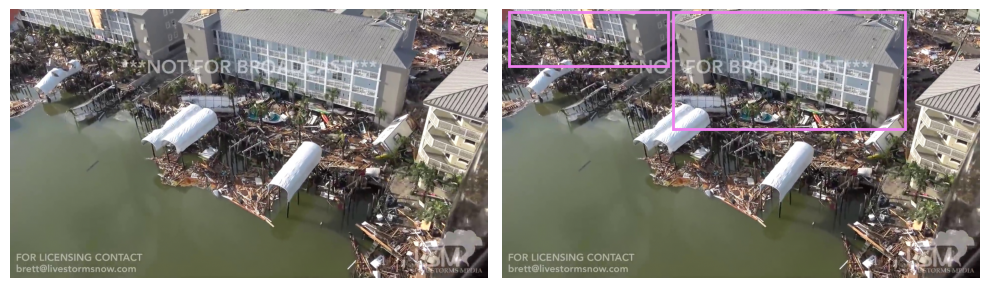

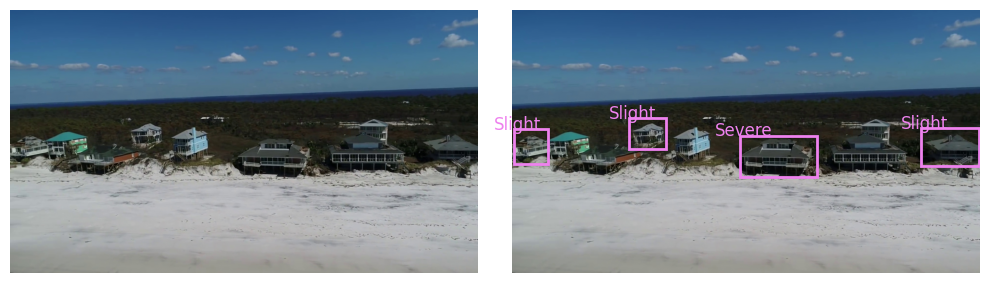

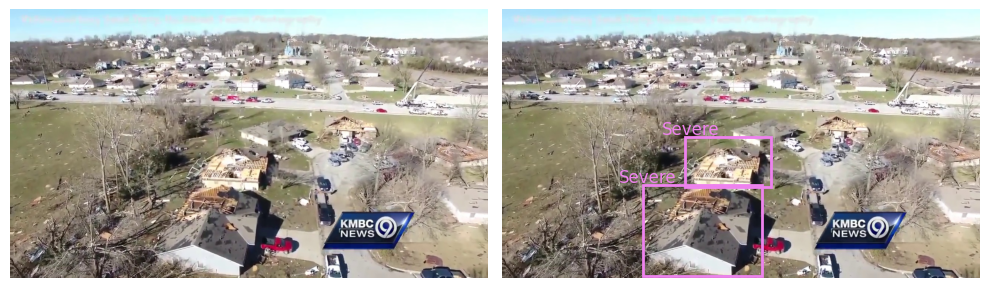

In [6]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(100)
fig3 = dataset.show_image(200)

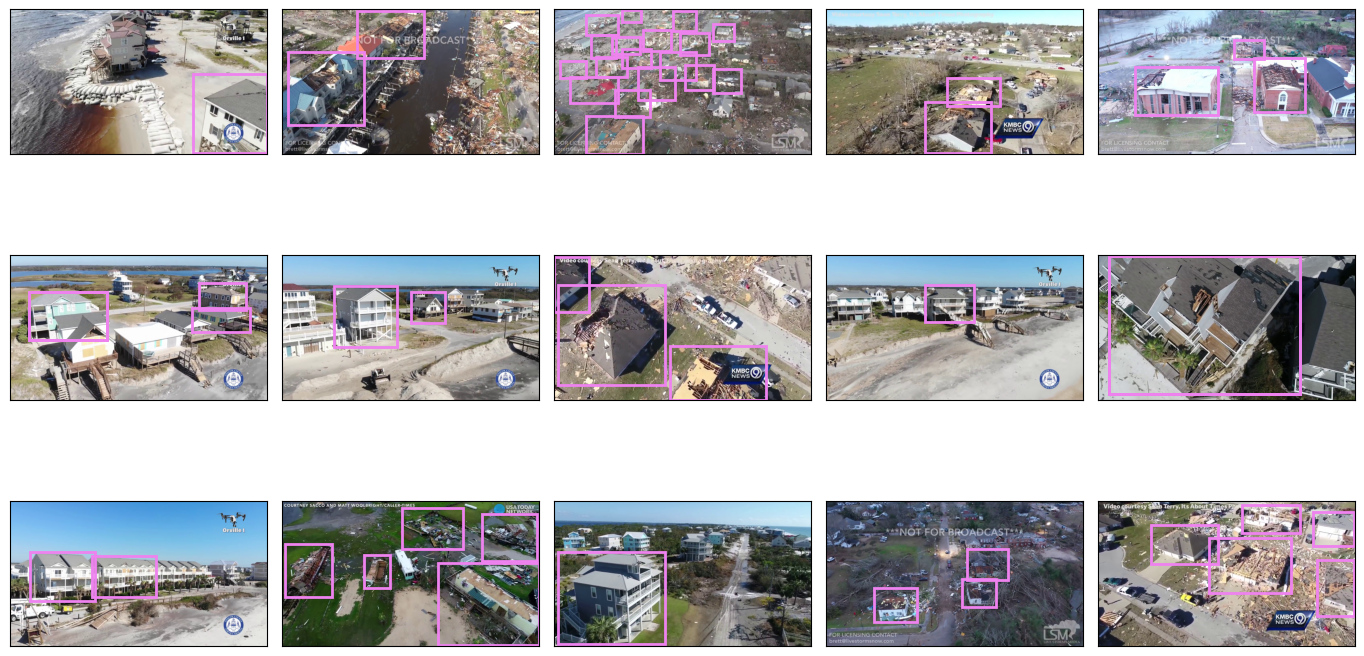

In [48]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [7]:
dataset.data_distribution_table()

,Label,Count
0,Slight,1591
1,Severe,391
2,Debris,194


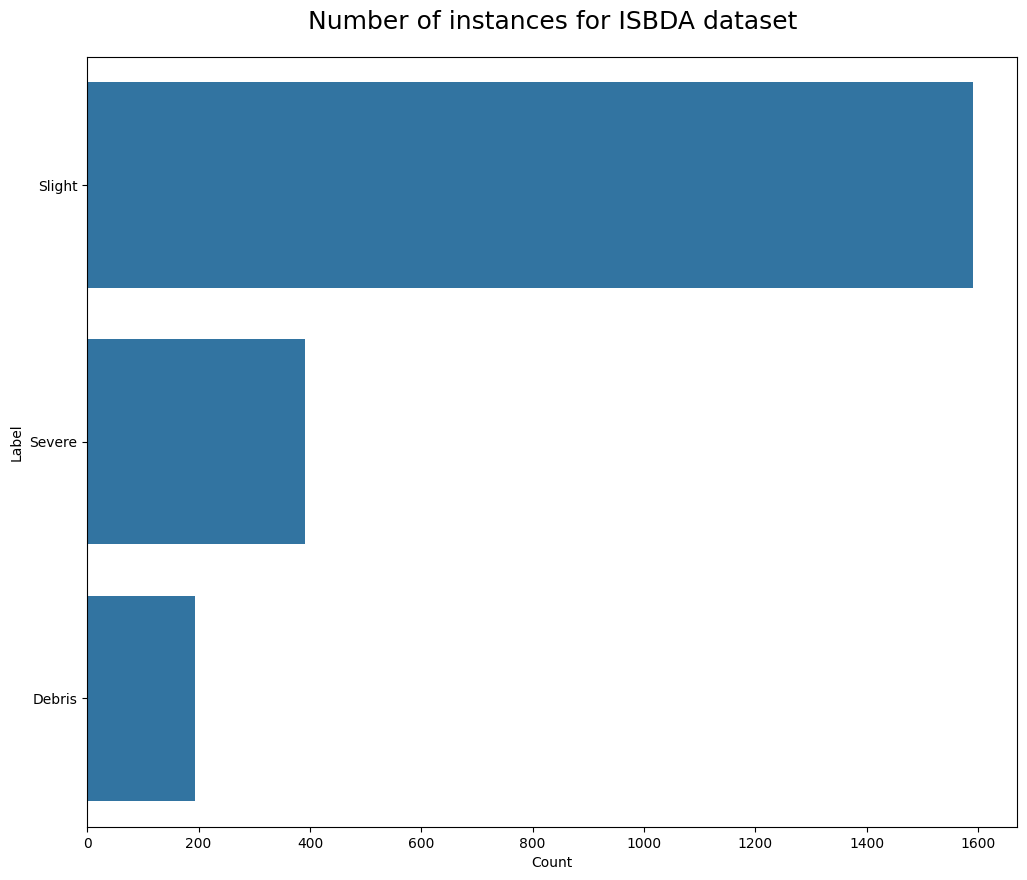

In [8]:
fig = dataset.data_distribution_barchart()

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/ISBDA/train/",
    "annotation_dir": "./data/ISBDA/annotations/instances_train.json",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = ISBDADataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 789


## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/ISBDA/"
model_config = {
    "num_classes": 4,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Training

In [25]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-07-15 08:34:39,886 INFO Starting training.
training: 100%|██████████| 99/99 [01:43<00:00,  1.05s/it]
2025-07-15 08:36:23,512 INFO epoch: 1, time: 104, loss:  0.44414
testing on train set: 100%|██████████| 99/99 [01:39<00:00,  1.00s/it]
2025-07-15 08:38:06,643 INFO map:0.27779892086982727, map_50:0.47155892848968506, map_75:0.31483718752861023, map_small:0.07766232639551163, map_medium:0.25907593965530396, map_large:0.30139848589897156, mar_1:0.16767774522304535, mar_10:0.39247050881385803, mar_100:0.4004066288471222, mar_small:0.18000000715255737, mar_medium:0.39450404047966003, mar_large:0.4034910798072815, map_per_class:tensor(0.4944), tensor(0.2843), tensor(0.0546), mar_100_per_class:tensor(0.6379), tensor(0.3979), tensor(0.1654), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), tensor(3, dtype=torch.int32)
training: 100%|██████████| 99/99 [01:39<00:00,  1.01s/it]
2025-07-15 08:39:46,513 INFO epoch: 2, time: 100, loss:  0.26393
testing on train set: 100%|████

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/ISBDA/val/",
    "annotation_dir": "./data/ISBDA/annotations/instances_val.json",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = ISBDADataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/ISBDA/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 241


2025-07-15 09:08:47,292 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/ISBDA/checkpoint.pth.tar
2025-07-15 09:08:47,569 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/ISBDA/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 31/31 [00:11<00:00,  2.79it/s]


[{'map': 0.1450938731431961,
  'map_50': 0.2507833242416382,
  'map_75': 0.1609354466199875,
  'map_small': 0.0,
  'map_medium': 0.0932687520980835,
  'map_large': 0.24041196703910828,
  'mar_1': 0.12612715363502502,
  'mar_10': 0.2203352302312851,
  'mar_100': 0.2203352302312851,
  'mar_small': 0.0,
  'mar_medium': 0.1617131382226944,
  'mar_large': 0.3185144364833832,
  'map_per_class': [tensor(0.2792), tensor(0.0887), tensor(0.0673)],
  'mar_100_per_class': [tensor(0.3947), tensor(0.1288), tensor(0.1375)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32)]}]

## Predictions

2025-07-15 09:09:02,852 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/ISBDA/checkpoint.pth.tar
2025-07-15 09:09:03,138 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/ISBDA/checkpoint.pth.tar at epoch 11


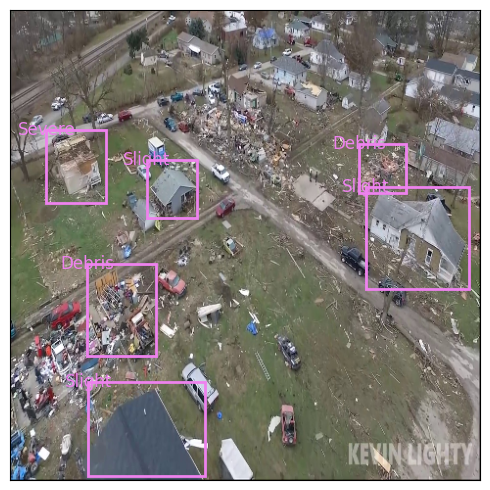

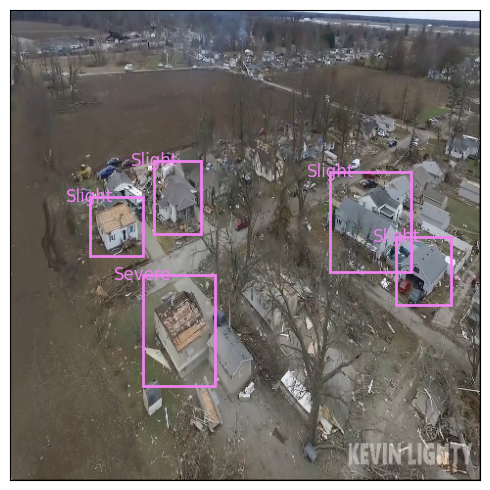

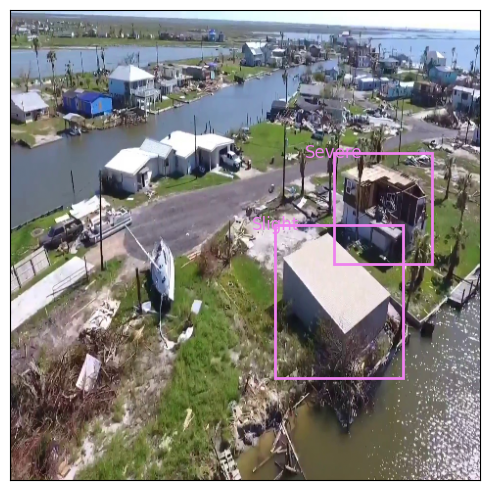

In [ ]:
model_config = {
    "num_classes": 4,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/ISBDA/checkpoint.pth.tar"
labels = ["No-damage", "Slight", "Severe", "Debris"]
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/ISBDA/val/7_360.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/ISBDA/val/7_2970.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/ISBDA/val/9_4500.jpg')
fig = model.detect_objects(image, labels, transform)